In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Plotting style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving hospital_data.csv to hospital_data.csv


In [3]:
df = pd.read_csv("hospital_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (97, 6)


,Month,Department,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation
0,Jan,Emergency,1055.00,44.40,35,88.70
1,Feb,Emergency,967.00,42.80,36,81.50
2,Mar,Emergency,960.00,43.60,32,91.20
3,Apr,Emergency,824.00,45.20,35,74.00
4,May,Emergency,NaN,42.00,34,67.60


In [4]:
# Check dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (97, 6)

Column Names:
['Month', 'Department', 'Patient_Volume', 'Average_Treatment_Duration', 'Staff_Count', 'Equipment_Utilisation']

Data Types:
Month                          object
Department                     object
Patient_Volume                float64
Average_Treatment_Duration    float64
Staff_Count                     int64
Equipment_Utilisation         float64
dtype: object

First 5 Rows:


,Month,Department,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation
0,Jan,Emergency,1055.00,44.40,35,88.70
1,Feb,Emergency,967.00,42.80,36,81.50
2,Mar,Emergency,960.00,43.60,32,91.20
3,Apr,Emergency,824.00,45.20,35,74.00
4,May,Emergency,NaN,42.00,34,67.60



Missing Values:
Month                         0
Department                    0
Patient_Volume                1
Average_Treatment_Duration    0
Staff_Count                   0
Equipment_Utilisation         1
dtype: int64

Duplicate Rows: 1


In [5]:
# ============================================
# DATA CLEANING
# ============================================

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Clean Department and Month
df["Department"] = df["Department"].astype(str).str.strip().str.title()
df["Month"] = df["Month"].astype(str).str.strip().str[:3].str.title()

# Numerical columns
num_cols = [
    "Patient_Volume",
    "Average_Treatment_Duration",
    "Staff_Count",
    "Equipment_Utilisation"
]

# Convert numerical columns to numbers
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace impossible negative values with missing values
df.loc[(df[num_cols] < 0).any(axis=1), num_cols] = np.nan

# Equipment utilisation cannot exceed 100%
df.loc[
    df["Equipment_Utilisation"] > 100,
    "Equipment_Utilisation"
] = np.nan

# Remove duplicate rows
df = df.drop_duplicates()

print("Data cleaning completed!")
print("Shape after cleaning:", df.shape)

print("\nMissing values after validation:")
print(df.isnull().sum())

Data cleaning completed!
Shape after cleaning: (96, 6)

Missing values after validation:
Month                         0
Department                    0
Patient_Volume                2
Average_Treatment_Duration    1
Staff_Count                   1
Equipment_Utilisation         3
dtype: int64


In [6]:
# ============================================
# HANDLE MISSING VALUES
# ============================================

for col in num_cols:
    df[col] = df.groupby("Department")[col].transform(
        lambda x: x.fillna(x.median())
    )

# If any values still remain missing, use overall median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Month                         0
Department                    0
Patient_Volume                0
Average_Treatment_Duration    0
Staff_Count                   0
Equipment_Utilisation         0
dtype: int64


In [7]:
# ============================================
# MONTH NUMBER
# ============================================

MONTHS = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

month_map = {month: i + 1 for i, month in enumerate(MONTHS)}

df["Month_Num"] = df["Month"].map(month_map)

# Remove invalid months
df = df.dropna(subset=["Month_Num"])

df["Month_Num"] = df["Month_Num"].astype(int)

print("Month conversion completed!")
display(df.head())

Month conversion completed!


,Month,Department,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation,Month_Num
0,Jan,Emergency,1055.00,44.40,35.00,88.70,1
1,Feb,Emergency,967.00,42.80,36.00,81.50,2
2,Mar,Emergency,960.00,43.60,32.00,91.20,3
3,Apr,Emergency,824.00,45.20,35.00,74.00,4
4,May,Emergency,941.00,42.00,34.00,67.60,5


In [8]:
print("========== FINAL DATA VALIDATION ==========")

print("\nShape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDepartments:")
print(df["Department"].unique())

print("\nMonths:")
print(df["Month"].unique())

print("\nStatistical Summary:")
display(df[num_cols].describe().round(2))

========== FINAL DATA VALIDATION ==========

Shape: (96, 7)

Missing Values:
Month                         0
Department                    0
Patient_Volume                0
Average_Treatment_Duration    0
Staff_Count                   0
Equipment_Utilisation         0
Month_Num                     0
dtype: int64

Duplicate Rows: 0

Departments:
['Emergency' 'Cardiology' 'Orthopaedics' 'Paediatrics' 'Radiology'
 'Oncology' 'Maternity' 'General Medicine']

Months:
['Jan' 'Feb' 'Mar' 'Apr' 'May' 'Jun' 'Jul' 'Aug' 'Sep' 'Oct' 'Nov' 'Dec']

Statistical Summary:


,Patient_Volume,Average_Treatment_Duration,Staff_Count,Equipment_Utilisation
count,96.00,96.00,96.00,96.00
mean,489.23,51.08,19.41,81.46
std,233.52,20.66,7.90,15.07
min,210.00,24.10,9.00,45.20
25%,300.75,36.92,14.00,68.88
50%,411.00,46.85,16.50,84.30
75%,648.75,63.55,23.50,96.78
max,1073.00,99.20,36.00,99.00


In [9]:
# ============================================
# FEATURE ENGINEERING
# ============================================

# Patients handled by one staff member
df["Patients_per_Staff"] = (
    df["Patient_Volume"] / df["Staff_Count"]
)

# Staff available for each patient
df["Staff_to_Patient"] = (
    df["Staff_Count"] / df["Patient_Volume"]
)

# Total workload in hours per month
df["Workload_Hours"] = (
    df["Patient_Volume"]
    * df["Average_Treatment_Duration"]
    / 60
)

# Workload handled by each staff member
df["Workload_per_Staff"] = (
    df["Workload_Hours"] / df["Staff_Count"]
)

print("Feature engineering completed!")

display(
    df[
        [
            "Department",
            "Month",
            "Patient_Volume",
            "Staff_Count",
            "Patients_per_Staff",
            "Staff_to_Patient",
            "Workload_Hours",
            "Workload_per_Staff"
        ]
    ].head(10)
)

Feature engineering completed!


,Department,Month,Patient_Volume,Staff_Count,Patients_per_Staff,Staff_to_Patient,Workload_Hours,Workload_per_Staff
0,Emergency,Jan,1055.00,35.00,30.14,0.03,780.70,22.31
1,Emergency,Feb,967.00,36.00,26.86,0.04,689.79,19.16
2,Emergency,Mar,960.00,32.00,30.00,0.03,697.60,21.80
3,Emergency,Apr,824.00,35.00,23.54,0.04,620.75,17.74
4,Emergency,May,941.00,34.00,27.68,0.04,658.70,19.37
5,Emergency,Jun,651.00,34.00,19.15,0.05,456.79,13.43
6,Emergency,Jul,735.00,36.00,20.42,0.05,558.60,15.52
7,Emergency,Aug,802.00,35.00,22.91,0.04,525.31,15.01
8,Emergency,Sep,897.00,34.00,26.38,0.04,621.92,18.29
9,Emergency,Oct,941.00,34.00,27.68,0.04,677.52,19.93


In [10]:
# ============================================
# DEPARTMENT-WISE ANALYSIS
# ============================================

dept_summary = df.groupby("Department").agg(
    Avg_Volume=("Patient_Volume", "mean"),
    Avg_Treatment_Duration=("Average_Treatment_Duration", "mean"),
    Avg_Staff=("Staff_Count", "mean"),
    Avg_Equipment_Utilisation=("Equipment_Utilisation", "mean"),
    Avg_Patients_per_Staff=("Patients_per_Staff", "mean"),
    Avg_Workload_per_Staff=("Workload_per_Staff", "mean")
).round(2)

print("Department-wise Summary:")
display(dept_summary)

Department-wise Summary:


,Avg_Volume,Avg_Treatment_Duration,Avg_Staff,Avg_Equipment_Utilisation,Avg_Patients_per_Staff,Avg_Workload_per_Staff
Department,,,,,,
Cardiology,373.77,53.17,14.15,90.47,26.54,23.12
Emergency,904.92,43.50,34.25,79.41,26.51,19.26
General Medicine,710.75,39.92,29.67,70.82,24.07,16.03
Maternity,305.33,59.46,19.83,69.55,15.56,15.41
Oncology,234.09,90.85,16.09,90.15,14.64,22.16
Orthopaedics,305.92,70.29,13.25,96.88,23.26,27.27
Paediatrics,454.08,29.31,17.08,60.98,26.59,12.91
Radiology,613.33,25.31,11.08,93.40,56.01,23.62


In [11]:
# ============================================
# HIGH EQUIPMENT UTILISATION
# ============================================

HIGH_UTIL_THRESHOLD = 85

dept_summary["Months_Above_85"] = (
    df.groupby("Department")["Equipment_Utilisation"]
    .apply(lambda x: (x > HIGH_UTIL_THRESHOLD).sum())
)

dept_summary = dept_summary.sort_values(
    "Avg_Equipment_Utilisation",
    ascending=False
)

print("Departments with equipment utilisation above 85%:")
display(
    dept_summary[
        [
            "Avg_Equipment_Utilisation",
            "Months_Above_85",
            "Avg_Patients_per_Staff",
            "Avg_Workload_per_Staff"
        ]
    ]
)

Departments with equipment utilisation above 85%:


,Avg_Equipment_Utilisation,Months_Above_85,Avg_Patients_per_Staff,Avg_Workload_per_Staff
Department,,,,
Orthopaedics,96.88,11,23.26,27.27
Radiology,93.40,11,56.01,23.62
Cardiology,90.47,10,26.54,23.12
Oncology,90.15,8,14.64,22.16
Emergency,79.41,5,26.51,19.26
General Medicine,70.82,0,24.07,16.03
Maternity,69.55,1,15.56,15.41
Paediatrics,60.98,0,26.59,12.91


In [12]:
consistent_high_util = dept_summary[
    dept_summary["Months_Above_85"] >= 9
].index.tolist()

print(
    "Departments with utilisation above 85% "
    "in at least 9 months:"
)

if consistent_high_util:
    for department in consistent_high_util:
        print("-", department)
else:
    print("No department meets this condition.")

Departments with utilisation above 85% in at least 9 months:
- Orthopaedics
- Radiology
- Cardiology


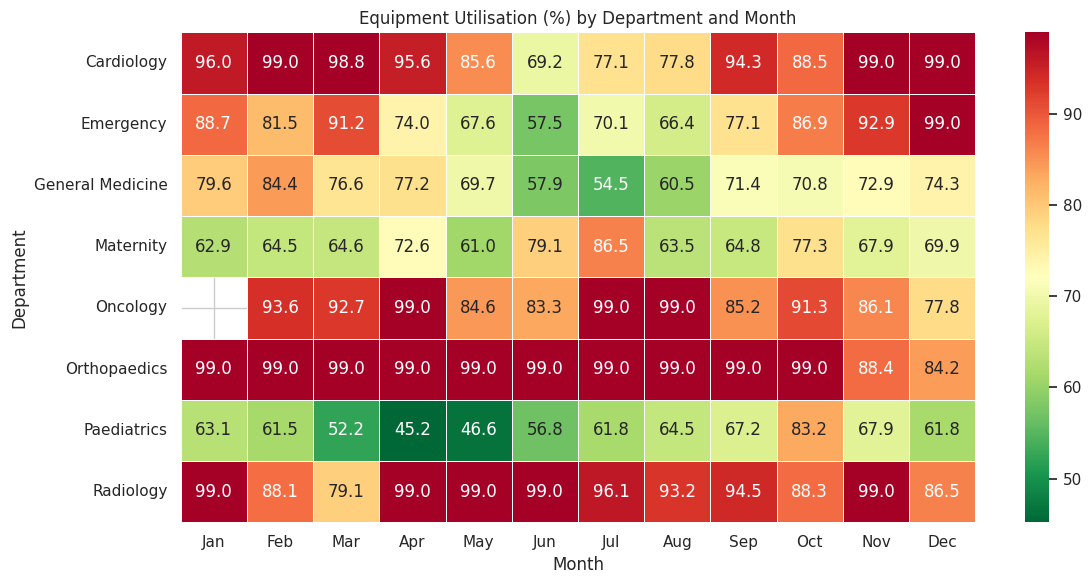

In [13]:
# ============================================
# VISUALISATION 1: EQUIPMENT UTILISATION HEATMAP
# ============================================

heatmap_data = df.pivot_table(
    index="Department",
    columns="Month_Num",
    values="Equipment_Utilisation",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    xticklabels=MONTHS,
    linewidths=0.5
)

plt.title("Equipment Utilisation (%) by Department and Month")
plt.xlabel("Month")
plt.ylabel("Department")
plt.tight_layout()

plt.show()

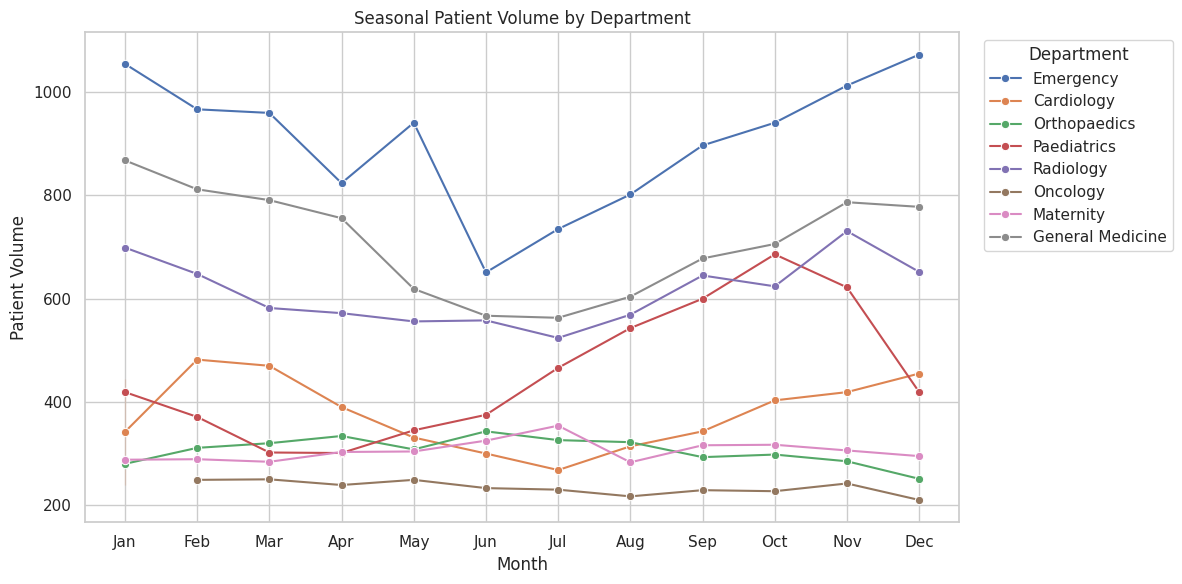

In [14]:
# ============================================
# VISUALISATION 2: SEASONAL PATIENT VOLUME
# ============================================

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="Month_Num",
    y="Patient_Volume",
    hue="Department",
    marker="o"
)

plt.xticks(
    range(1, 13),
    MONTHS
)

plt.title("Seasonal Patient Volume by Department")
plt.xlabel("Month")
plt.ylabel("Patient Volume")
plt.legend(title="Department", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

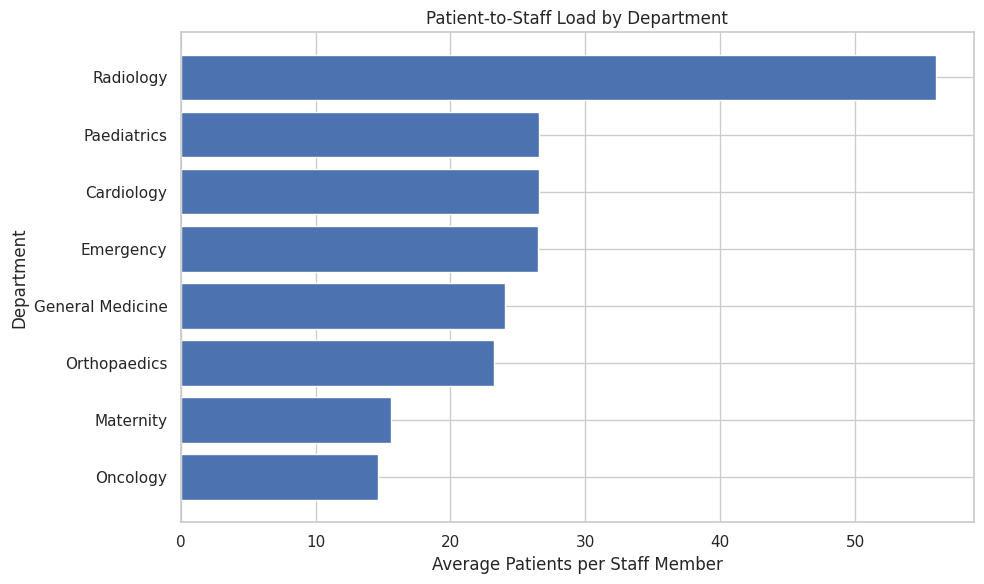

In [15]:
# ============================================
# VISUALISATION 3: PATIENT-TO-STAFF LOAD
# ============================================

patients_staff = (
    df.groupby("Department")["Patients_per_Staff"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    patients_staff.index,
    patients_staff.values
)

plt.xlabel("Average Patients per Staff Member")
plt.ylabel("Department")
plt.title("Patient-to-Staff Load by Department")

plt.tight_layout()
plt.show()

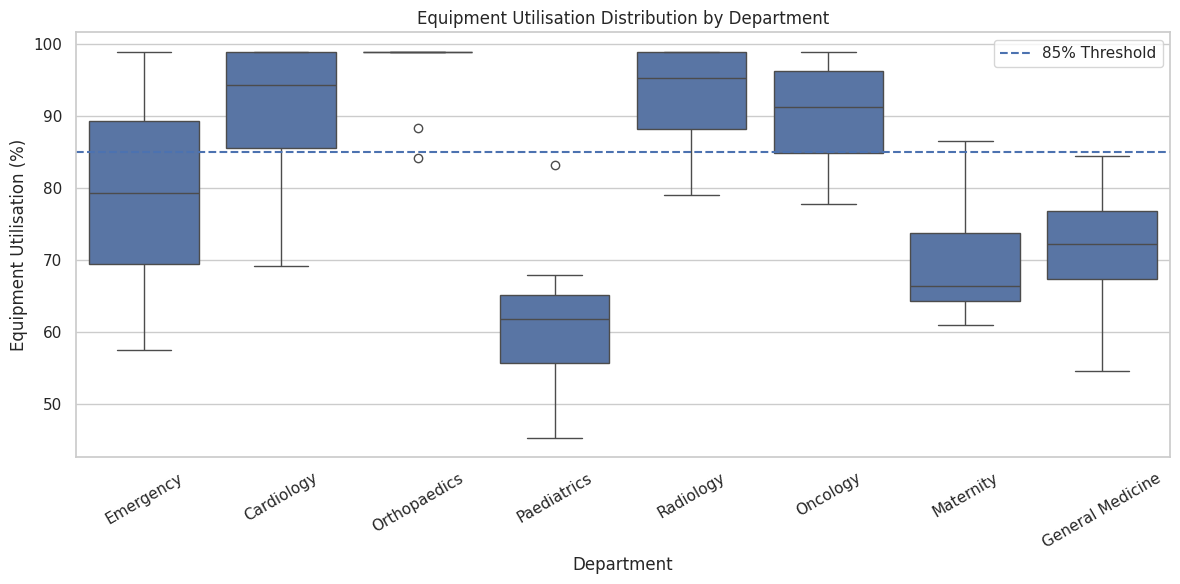

In [16]:
# ============================================
# VISUALISATION 4: UTILISATION DISTRIBUTION
# ============================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Department",
    y="Equipment_Utilisation"
)

plt.axhline(
    HIGH_UTIL_THRESHOLD,
    linestyle="--",
    label=f"{HIGH_UTIL_THRESHOLD}% Threshold"
)

plt.title("Equipment Utilisation Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Equipment Utilisation (%)")
plt.xticks(rotation=30)
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
# ============================================
# SAVE VISUALISATIONS
# ============================================

# Visualization 1
plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    xticklabels=MONTHS,
    linewidths=0.5
)
plt.title("Equipment Utilisation (%) by Department and Month")
plt.xlabel("Month")
plt.ylabel("Department")
plt.tight_layout()
plt.savefig("viz1_utilisation_heatmap.png", dpi=300)
plt.close()

# Visualization 2
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="Month_Num",
    y="Patient_Volume",
    hue="Department",
    marker="o"
)
plt.xticks(range(1, 13), MONTHS)
plt.title("Seasonal Patient Volume by Department")
plt.xlabel("Month")
plt.ylabel("Patient Volume")
plt.tight_layout()
plt.savefig("viz2_seasonal_volume.png", dpi=300)
plt.close()

# Visualization 3
plt.figure(figsize=(10, 6))
plt.barh(patients_staff.index, patients_staff.values)
plt.xlabel("Average Patients per Staff Member")
plt.ylabel("Department")
plt.title("Patient-to-Staff Load by Department")
plt.tight_layout()
plt.savefig("viz3_patients_per_staff.png", dpi=300)
plt.close()

# Visualization 4
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="Department",
    y="Equipment_Utilisation"
)
plt.axhline(
    HIGH_UTIL_THRESHOLD,
    linestyle="--",
    label=f"{HIGH_UTIL_THRESHOLD}% Threshold"
)
plt.title("Equipment Utilisation Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Equipment Utilisation (%)")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.savefig("viz4_utilisation_boxplot.png", dpi=300)
plt.close()

print("All 4 visualisations saved successfully!")

All 4 visualisations saved successfully!


In [18]:
# ============================================
# STATISTICAL ANALYSIS - ANOVA
# ============================================

# Create groups for each department
groups = [
    group["Equipment_Utilisation"].values
    for _, group in df.groupby("Department")
]

# One-way ANOVA
f_stat, p_anova = stats.f_oneway(*groups)

print("========== ONE-WAY ANOVA ==========")
print("F-statistic:", round(f_stat, 3))
print("p-value:", p_anova)

if p_anova < 0.05:
    print("\nResult: Significant difference exists between departments.")
else:
    print("\nResult: No statistically significant difference was detected.")

========== ONE-WAY ANOVA ==========
F-statistic: 26.266
p-value: 4.59197052893197e-19

Result: Significant difference exists between departments.


In [19]:
# ============================================
# KRUSKAL-WALLIS TEST
# ============================================

h_stat, p_kw = stats.kruskal(*groups)

print("========== KRUSKAL-WALLIS TEST ==========")
print("H-statistic:", round(h_stat, 3))
print("p-value:", p_kw)

if p_kw < 0.05:
    print("\nResult: Significant difference exists between departments.")
else:
    print("\nResult: No statistically significant difference was detected.")

========== KRUSKAL-WALLIS TEST ==========
H-statistic: 64.113
p-value: 2.2668044836804535e-11

Result: Significant difference exists between departments.


In [20]:
# ============================================
# SEASONAL ANALYSIS
# ============================================

seasonal_data = df.pivot_table(
    index="Month_Num",
    columns="Department",
    values="Patient_Volume",
    aggfunc="mean"
)

peak_months = seasonal_data.idxmax()

peak_month_names = peak_months.map(
    lambda x: MONTHS[int(x) - 1]
)

print("========== PEAK PATIENT MONTH ==========")

for department, month in peak_month_names.items():
    print(f"{department}: {month}")

========== PEAK PATIENT MONTH ==========
Cardiology: Feb
Emergency: Dec
General Medicine: Jan
Maternity: Jul
Oncology: Mar
Orthopaedics: Jun
Paediatrics: Oct
Radiology: Nov


In [21]:
# ============================================
# MONTHLY PATIENT VOLUME
# ============================================

monthly_volume = (
    df.groupby(["Month_Num", "Month"])["Patient_Volume"]
    .sum()
    .reset_index()
    .sort_values("Month_Num")
)

display(monthly_volume)

,Month_Num,Month,Patient_Volume
0,1,Jan,4293.00
1,2,Feb,4129.00
2,3,Mar,3959.00
3,4,Apr,3719.00
4,5,May,3653.00
5,6,Jun,3352.00
6,7,Jul,3466.00
7,8,Aug,3654.00
8,9,Sep,4001.00
9,10,Oct,4202.00


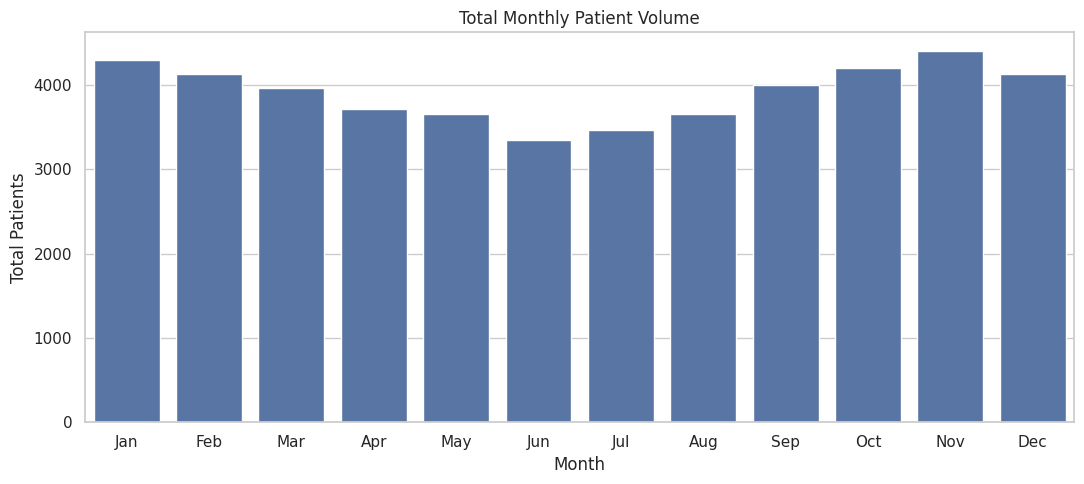

In [22]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=monthly_volume,
    x="Month",
    y="Patient_Volume",
    order=MONTHS
)

plt.title("Total Monthly Patient Volume")
plt.xlabel("Month")
plt.ylabel("Total Patients")

plt.tight_layout()
plt.show()

In [23]:
# ============================================
# RANDOM FOREST - TARGET CREATION
# ============================================

HIGH_UTIL_THRESHOLD = 85

df["High_Util"] = (
    df["Equipment_Utilisation"] > HIGH_UTIL_THRESHOLD
).astype(int)

print("Target variable created!")

print("\nTarget distribution:")
print(df["High_Util"].value_counts())

print("\nTarget percentage:")
print(
    (df["High_Util"].value_counts(normalize=True) * 100)
    .round(2)
)

Target variable created!

Target distribution:
High_Util
0    50
1    46
Name: count, dtype: int64

Target percentage:
High_Util
0   52.08
1   47.92
Name: proportion, dtype: float64


In [24]:
# ============================================
# PREPARE FEATURES
# ============================================

features = [
    "Department",
    "Month_Num",
    "Patient_Volume",
    "Average_Treatment_Duration",
    "Staff_Count",
    "Patients_per_Staff",
    "Staff_to_Patient",
    "Workload_Hours",
    "Workload_per_Staff"
]

X = df[features].copy()
y = df["High_Util"]

# Convert Department into numerical dummy variables
X = pd.get_dummies(
    X,
    columns=["Department"],
    dtype=int
)

print("Feature matrix shape:", X.shape)

print("\nFeatures used:")
print(X.columns.tolist())

Feature matrix shape: (96, 16)

Features used:
['Month_Num', 'Patient_Volume', 'Average_Treatment_Duration', 'Staff_Count', 'Patients_per_Staff', 'Staff_to_Patient', 'Workload_Hours', 'Workload_per_Staff', 'Department_Cardiology', 'Department_Emergency', 'Department_General Medicine', 'Department_Maternity', 'Department_Oncology', 'Department_Orthopaedics', 'Department_Paediatrics', 'Department_Radiology']


In [25]:
# ============================================
# TRAIN / TEST SPLIT
# ============================================

stratify_value = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=stratify_value
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 72
Testing samples: 24

Training target distribution:
High_Util
0    37
1    35
Name: count, dtype: int64

Testing target distribution:
High_Util
0    13
1    11
Name: count, dtype: int64


In [26]:
# ============================================
# TRAIN RANDOM FOREST
# ============================================

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

rf.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
# ============================================
# PREDICTIONS
# ============================================

y_pred = rf.predict(X_test)

print("Predictions generated successfully!")

print("\nActual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

Predictions generated successfully!

Actual values:
[1 1 1 0 0 1 0 1 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0 1]

Predicted values:
[1 1 1 0 0 1 0 1 0 1 1 0 1 0 1 0 1 0 0 0 0 1 0 1]


In [28]:
# ============================================
# MODEL ACCURACY
# ============================================

accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Test Accuracy:")
print(f"{accuracy * 100:.2f}%")

Random Forest Test Accuracy:
87.50%


In [29]:
print("Test Accuracy:", f"{accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal Utilisation", "High Utilisation"],
    zero_division=0
))

Test Accuracy: 87.50%

Confusion Matrix:
[[11  2]
 [ 1 10]]

Classification Report:
                    precision    recall  f1-score   support

Normal Utilisation       0.92      0.85      0.88        13
  High Utilisation       0.83      0.91      0.87        11

          accuracy                           0.88        24
         macro avg       0.88      0.88      0.87        24
      weighted avg       0.88      0.88      0.88        24



In [30]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Fold accuracies:", np.round(cv_scores, 3))
print("Mean CV accuracy:", f"{cv_scores.mean() * 100:.2f}%")

Fold accuracies: [0.9   1.    0.947 0.947 0.789]
Mean CV accuracy: 91.68%


In [31]:
# ============================================
# DETAILED MODEL EVALUATION
# ============================================

print("Test Accuracy:", f"{accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal Utilisation", "High Utilisation"],
        zero_division=0
    )
)

Test Accuracy: 87.50%

Confusion Matrix:
[[11  2]
 [ 1 10]]

Classification Report:
                    precision    recall  f1-score   support

Normal Utilisation       0.92      0.85      0.88        13
  High Utilisation       0.83      0.91      0.87        11

          accuracy                           0.88        24
         macro avg       0.88      0.88      0.87        24
      weighted avg       0.88      0.88      0.88        24



In [32]:
# ============================================
# TARGET DISTRIBUTION
# ============================================

print("Overall target distribution:")
print(df["High_Util"].value_counts())

print("\nPercentage distribution:")
print(
    df["High_Util"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Overall target distribution:
High_Util
0    50
1    46
Name: count, dtype: int64

Percentage distribution:
High_Util
0   52.08
1   47.92
Name: proportion, dtype: float64


In [33]:
# ============================================
# 5-FOLD CROSS VALIDATION
# ============================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    rf,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation accuracies:")
print(np.round(cv_scores, 3))

print(
    "\nMean CV Accuracy:",
    f"{cv_scores.mean() * 100:.2f}%"
)

Cross-validation accuracies:
[0.9   1.    0.947 0.947 0.789]

Mean CV Accuracy: 91.68%


In [34]:
# ============================================
# CLASSIFICATION REPORT
# ============================================

print("========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Normal Utilisation",
            "High Utilisation"
        ],
        zero_division=0
    )
)

========== CLASSIFICATION REPORT ==========
                    precision    recall  f1-score   support

Normal Utilisation       0.92      0.85      0.88        13
  High Utilisation       0.83      0.91      0.87        11

          accuracy                           0.88        24
         macro avg       0.88      0.88      0.87        24
      weighted avg       0.88      0.88      0.88        24



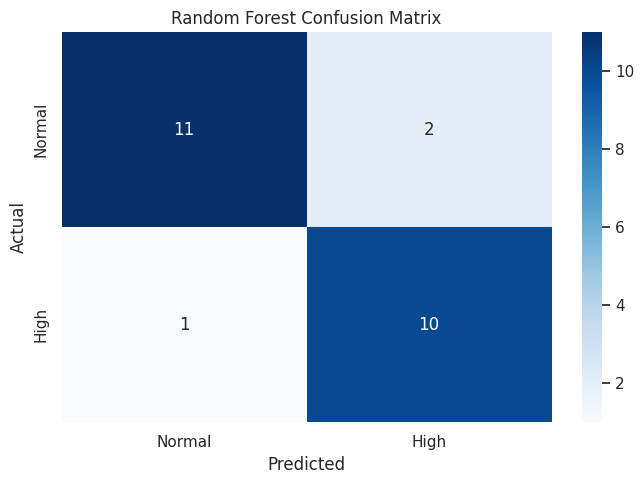

In [35]:
# ============================================
# CONFUSION MATRIX
# ============================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "High"
    ],
    yticklabels=[
        "Normal",
        "High"
    ]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [36]:
# ============================================
# FEATURE IMPORTANCE
# ============================================

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("========== FEATURE IMPORTANCE ==========")
display(importance.to_frame("Importance").head(10))

========== FEATURE IMPORTANCE ==========


,Importance
Workload_per_Staff,0.44
Staff_Count,0.17
Average_Treatment_Duration,0.08
Workload_Hours,0.06
Staff_to_Patient,0.06
Patients_per_Staff,0.06
Patient_Volume,0.04
Department_Paediatrics,0.02
Department_Maternity,0.02
Department_Orthopaedics,0.02


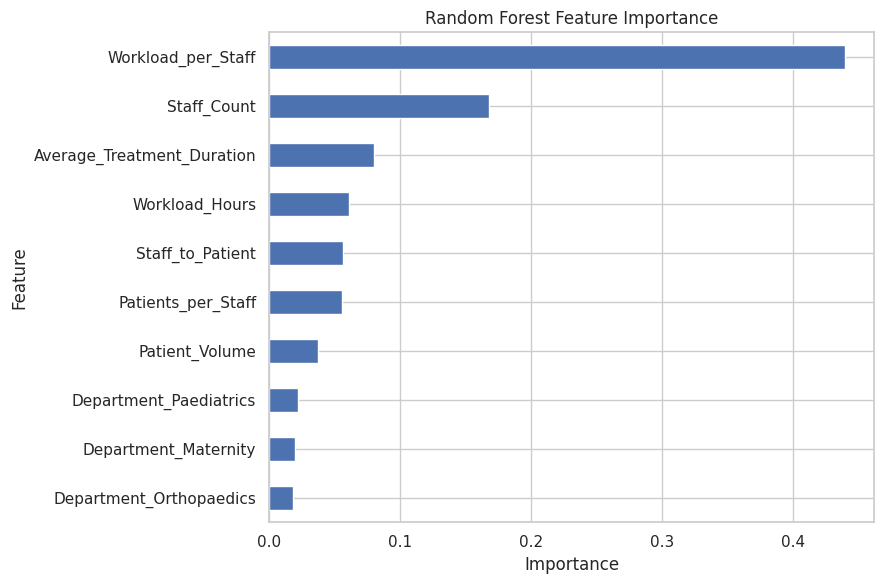

In [37]:
plt.figure(figsize=(9, 6))

importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [38]:
# ============================================
# RESOURCE PRESSURE SCORE
# ============================================

resource = df.groupby("Department").agg(
    Avg_Patient_Volume=("Patient_Volume", "mean"),
    Avg_Equipment_Utilisation=("Equipment_Utilisation", "mean"),
    Avg_Staff=("Staff_Count", "mean"),
    Avg_Patients_per_Staff=("Patients_per_Staff", "mean"),
    Avg_Workload_per_Staff=("Workload_per_Staff", "mean"),
    Months_Above_85=("Equipment_Utilisation",
                     lambda x: (x > HIGH_UTIL_THRESHOLD).sum())
)

# Convert indicators to percentile ranks
resource["Utilisation_Rank"] = (
    resource["Avg_Equipment_Utilisation"].rank(pct=True)
)

resource["Patient_Load_Rank"] = (
    resource["Avg_Patients_per_Staff"].rank(pct=True)
)

resource["Workload_Rank"] = (
    resource["Avg_Workload_per_Staff"].rank(pct=True)
)

# Overall resource pressure score
resource["Resource_Pressure_Score"] = (
    resource["Utilisation_Rank"]
    + resource["Patient_Load_Rank"]
    + resource["Workload_Rank"]
) / 3

resource = resource.sort_values(
    "Resource_Pressure_Score",
    ascending=False
)

display(
    resource[
        [
            "Avg_Patient_Volume",
            "Avg_Equipment_Utilisation",
            "Avg_Staff",
            "Avg_Patients_per_Staff",
            "Avg_Workload_per_Staff",
            "Months_Above_85",
            "Resource_Pressure_Score"
        ]
    ].round(2)
)

,Avg_Patient_Volume,Avg_Equipment_Utilisation,Avg_Staff,Avg_Patients_per_Staff,Avg_Workload_per_Staff,Months_Above_85,Resource_Pressure_Score
Department,,,,,,,
Radiology,613.33,93.40,11.08,56.01,23.62,11,0.92
Orthopaedics,305.92,96.88,13.25,23.26,27.27,11,0.79
Cardiology,373.77,90.47,14.15,26.54,23.12,10,0.75
Emergency,904.92,79.41,34.25,26.51,19.26,5,0.54
Oncology,234.09,90.15,16.09,14.64,22.16,8,0.46
General Medicine,710.75,70.82,29.67,24.07,16.03,0,0.42
Paediatrics,454.08,60.98,17.08,26.59,12.91,0,0.38
Maternity,305.33,69.55,19.83,15.56,15.41,1,0.25


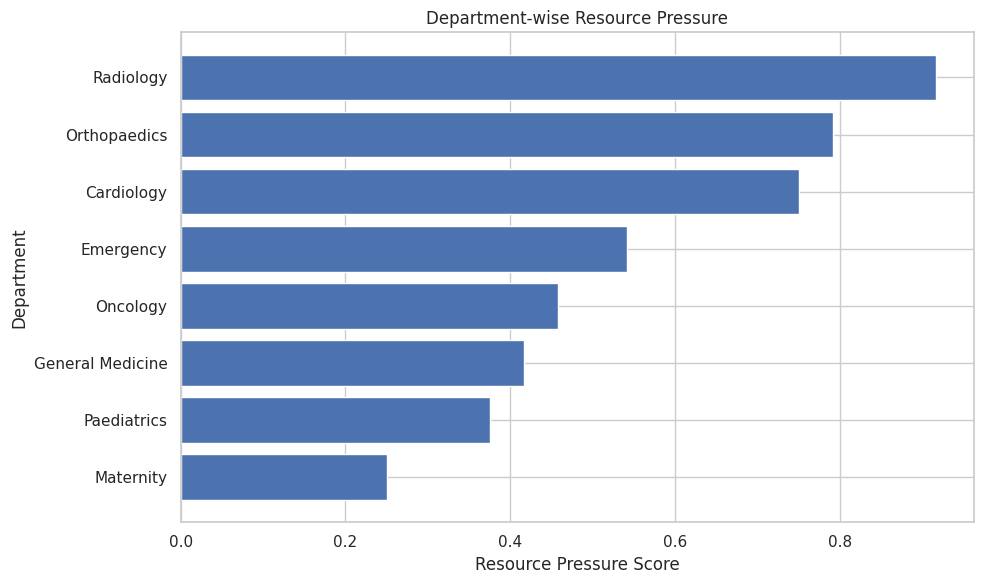

In [39]:
# ============================================
# RESOURCE PRESSURE VISUALIZATION
# ============================================

plt.figure(figsize=(10, 6))

plt.barh(
    resource.index[::-1],
    resource["Resource_Pressure_Score"][::-1]
)

plt.xlabel("Resource Pressure Score")
plt.ylabel("Department")
plt.title("Department-wise Resource Pressure")

plt.tight_layout()
plt.show()

In [40]:
# ============================================
# RESOURCE ALLOCATION PRIORITY
# ============================================

high_cutoff = resource["Resource_Pressure_Score"].quantile(0.67)
medium_cutoff = resource["Resource_Pressure_Score"].quantile(0.33)

def classify_pressure(score):
    if score >= high_cutoff:
        return "High"
    elif score >= medium_cutoff:
        return "Moderate"
    else:
        return "Lower"

resource["Resource_Priority"] = (
    resource["Resource_Pressure_Score"]
    .apply(classify_pressure)
)

print("========== RESOURCE ALLOCATION PRIORITY ==========")

display(
    resource[
        [
            "Avg_Equipment_Utilisation",
            "Avg_Patients_per_Staff",
            "Avg_Workload_per_Staff",
            "Months_Above_85",
            "Resource_Pressure_Score",
            "Resource_Priority"
        ]
    ].round(2)
)

========== RESOURCE ALLOCATION PRIORITY ==========


,Avg_Equipment_Utilisation,Avg_Patients_per_Staff,Avg_Workload_per_Staff,Months_Above_85,Resource_Pressure_Score,Resource_Priority
Department,,,,,,
Radiology,93.40,56.01,23.62,11,0.92,High
Orthopaedics,96.88,23.26,27.27,11,0.79,High
Cardiology,90.47,26.54,23.12,10,0.75,High
Emergency,79.41,26.51,19.26,5,0.54,Moderate
Oncology,90.15,14.64,22.16,8,0.46,Moderate
General Medicine,70.82,24.07,16.03,0,0.42,Lower
Paediatrics,60.98,26.59,12.91,0,0.38,Lower
Maternity,69.55,15.56,15.41,1,0.25,Lower


In [41]:
# ============================================
# ACTION PLAN
# ============================================

print("========== PRACTICAL ACTION PLAN ==========\n")

for department, row in resource.iterrows():

    if row["Resource_Priority"] == "High":
        print(
            f"{department}: High resource pressure. "
            f"Consider reviewing staffing levels, equipment capacity, "
            f"and workload during high-demand periods."
        )

    elif row["Resource_Priority"] == "Moderate":
        print(
            f"{department}: Moderate resource pressure. "
            f"Monitor patient load and equipment utilisation."
        )

    else:
        print(
            f"{department}: Lower relative resource pressure. "
            f"Continue monitoring demand and capacity."
        )

========== PRACTICAL ACTION PLAN ==========

Radiology: High resource pressure. Consider reviewing staffing levels, equipment capacity, and workload during high-demand periods.
Orthopaedics: High resource pressure. Consider reviewing staffing levels, equipment capacity, and workload during high-demand periods.
Cardiology: High resource pressure. Consider reviewing staffing levels, equipment capacity, and workload during high-demand periods.
Emergency: Moderate resource pressure. Monitor patient load and equipment utilisation.
Oncology: Moderate resource pressure. Monitor patient load and equipment utilisation.
General Medicine: Lower relative resource pressure. Continue monitoring demand and capacity.
Paediatrics: Lower relative resource pressure. Continue monitoring demand and capacity.
Maternity: Lower relative resource pressure. Continue monitoring demand and capacity.


In [42]:
# ============================================
# ACTION PLAN
# ============================================

print("========== PRACTICAL ACTION PLAN ==========\n")

for department, row in resource.iterrows():

    if row["Resource_Priority"] == "High":
        print(
            f"{department}: High resource pressure. "
            f"Consider reviewing staffing levels, equipment capacity, "
            f"and workload during high-demand periods."
        )

    elif row["Resource_Priority"] == "Moderate":
        print(
            f"{department}: Moderate resource pressure. "
            f"Monitor patient load and equipment utilisation."
        )

    else:
        print(
            f"{department}: Lower relative resource pressure. "
            f"Continue monitoring demand and capacity."
        )

========== PRACTICAL ACTION PLAN ==========

Radiology: High resource pressure. Consider reviewing staffing levels, equipment capacity, and workload during high-demand periods.
Orthopaedics: High resource pressure. Consider reviewing staffing levels, equipment capacity, and workload during high-demand periods.
Cardiology: High resource pressure. Consider reviewing staffing levels, equipment capacity, and workload during high-demand periods.
Emergency: Moderate resource pressure. Monitor patient load and equipment utilisation.
Oncology: Moderate resource pressure. Monitor patient load and equipment utilisation.
General Medicine: Lower relative resource pressure. Continue monitoring demand and capacity.
Paediatrics: Lower relative resource pressure. Continue monitoring demand and capacity.
Maternity: Lower relative resource pressure. Continue monitoring demand and capacity.


In [43]:
# ============================================
# SAVE RESULTS
# ============================================

df.to_csv(
    "hospital_cleaned.csv",
    index=False
)

resource.to_csv(
    "department_resource_analysis.csv"
)

importance.to_csv(
    "random_forest_feature_importance.csv"
)

print("Files saved successfully!")

print("\nCreated files:")
print("1. hospital_cleaned.csv")
print("2. department_resource_analysis.csv")
print("3. random_forest_feature_importance.csv")

Files saved successfully!

Created files:
1. hospital_cleaned.csv
2. department_resource_analysis.csv
3. random_forest_feature_importance.csv


In [44]:
# ============================================
# FINAL PROJECT SUMMARY
# ============================================

print("=" * 60)
print("HOSPITAL RESOURCE ALLOCATION - FINAL SUMMARY")
print("=" * 60)

print(f"\nDataset records: {len(df)}")
print(f"Departments: {df['Department'].nunique()}")

print(
    f"\nRandom Forest Test Accuracy: "
    f"{accuracy * 100:.2f}%"
)

print(
    f"Mean 5-Fold CV Accuracy: "
    f"{cv_scores.mean() * 100:.2f}%"
)

print(
    f"\nANOVA p-value: "
    f"{p_anova:.4g}"
)

print(
    f"Kruskal-Wallis p-value: "
    f"{p_kw:.4g}"
)

print("\nDepartments requiring the most attention:")
high_priority = resource[
    resource["Resource_Priority"] == "High"
]

for department in high_priority.index:
    print(f"- {department}")

print("\nTop predictive features:")
for feature, value in importance.head(5).items():
    print(f"- {feature}: {value:.3f}")

HOSPITAL RESOURCE ALLOCATION - FINAL SUMMARY

Dataset records: 96
Departments: 8

Random Forest Test Accuracy: 87.50%
Mean 5-Fold CV Accuracy: 91.68%

ANOVA p-value: 4.592e-19
Kruskal-Wallis p-value: 2.267e-11

Departments requiring the most attention:
- Radiology
- Orthopaedics
- Cardiology

Top predictive features:
- Workload_per_Staff: 0.440
- Staff_Count: 0.168
- Average_Treatment_Duration: 0.080
- Workload_Hours: 0.061
- Staff_to_Patient: 0.056


In [45]:
# ============================================
# FINAL DEPARTMENT COMPARISON
# ============================================

final_table = resource[
    [
        "Avg_Patient_Volume",
        "Avg_Equipment_Utilisation",
        "Avg_Staff",
        "Avg_Patients_per_Staff",
        "Avg_Workload_per_Staff",
        "Months_Above_85",
        "Resource_Pressure_Score",
        "Resource_Priority"
    ]
].copy()

final_table.columns = [
    "Avg Patient Volume",
    "Avg Equipment Utilisation (%)",
    "Avg Staff",
    "Patients per Staff",
    "Workload per Staff (Hours)",
    "Months >85%",
    "Resource Pressure Score",
    "Priority"
]

display(final_table.round(2))

,Avg Patient Volume,Avg Equipment Utilisation (%),Avg Staff,Patients per Staff,Workload per Staff (Hours),Months >85%,Resource Pressure Score,Priority
Department,,,,,,,,
Radiology,613.33,93.40,11.08,56.01,23.62,11,0.92,High
Orthopaedics,305.92,96.88,13.25,23.26,27.27,11,0.79,High
Cardiology,373.77,90.47,14.15,26.54,23.12,10,0.75,High
Emergency,904.92,79.41,34.25,26.51,19.26,5,0.54,Moderate
Oncology,234.09,90.15,16.09,14.64,22.16,8,0.46,Moderate
General Medicine,710.75,70.82,29.67,24.07,16.03,0,0.42,Lower
Paediatrics,454.08,60.98,17.08,26.59,12.91,0,0.38,Lower
Maternity,305.33,69.55,19.83,15.56,15.41,1,0.25,Lower


In [46]:
# ============================================
# KEY DEPARTMENT FINDINGS
# ============================================

highest_volume = resource["Avg_Patient_Volume"].idxmax()
highest_util = resource["Avg_Equipment_Utilisation"].idxmax()
highest_patient_load = resource["Avg_Patients_per_Staff"].idxmax()
highest_workload = resource["Avg_Workload_per_Staff"].idxmax()

print("KEY FINDINGS")
print("=" * 50)

print(
    f"Highest average patient volume: "
    f"{highest_volume}"
)

print(
    f"Highest average equipment utilisation: "
    f"{highest_util}"
)

print(
    f"Highest patients-per-staff load: "
    f"{highest_patient_load}"
)

print(
    f"Highest workload per staff member: "
    f"{highest_workload}"
)

KEY FINDINGS
Highest average patient volume: Emergency
Highest average equipment utilisation: Orthopaedics
Highest patients-per-staff load: Radiology
Highest workload per staff member: Orthopaedics


In [48]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# ---------------- PAGE CONFIG ----------------
st.set_page_config(
    page_title="Hospital Resource Allocation",
    page_icon="🏥",
    layout="wide"
)

# ---------------- LOAD DATA ----------------
df = pd.read_csv("hospital_cleaned.csv")

# ---------------- FEATURES ----------------
df["Patients_per_Staff"] = (
    df["Patient_Volume"] / df["Staff_Count"]
)

df["Workload_Hours"] = (
    df["Patient_Volume"]
    * df["Average_Treatment_Duration"] / 60
)

df["Workload_per_Staff"] = (
    df["Workload_Hours"] / df["Staff_Count"]
)

HIGH = 85

df["High_Util"] = (
    df["Equipment_Utilisation"] > HIGH
).astype(int)

# ---------------- HEADER ----------------
st.title("🏥 Hospital Resource Allocation Dashboard")
st.markdown(
    "### Data-driven analysis for hospital department resource planning"
)

st.divider()

# ---------------- KPI CARDS ----------------
total_patients = int(df["Patient_Volume"].sum())
departments = df["Department"].nunique()
avg_util = df["Equipment_Utilisation"].mean()
high_util = (df["Equipment_Utilisation"] > HIGH).sum()

c1, c2, c3, c4 = st.columns(4)

c1.metric("👥 Total Patients", f"{total_patients:,}")
c2.metric("🏢 Departments", departments)
c3.metric("⚙️ Avg Equipment Utilisation", f"{avg_util:.1f}%")
c4.metric("⚠️ High Utilisation Records", high_util)

st.divider()

# ---------------- DEPARTMENT SELECTOR ----------------
department = st.selectbox(
    "🏢 Select Department",
    sorted(df["Department"].unique())
)

dept_data = df[df["Department"] == department]

# ---------------- DEPARTMENT METRICS ----------------
st.subheader(f"📋 {department} Analysis")

a, b, c, d = st.columns(4)

a.metric(
    "Average Patients",
    f"{dept_data['Patient_Volume'].mean():.0f}"
)

b.metric(
    "Average Staff",
    f"{dept_data['Staff_Count'].mean():.0f}"
)

c.metric(
    "Equipment Utilisation",
    f"{dept_data['Equipment_Utilisation'].mean():.1f}%"
)

d.metric(
    "Patients / Staff",
    f"{dept_data['Patients_per_Staff'].mean():.1f}"
)

# ---------------- CHARTS ----------------
left, right = st.columns(2)

with left:
    st.subheader("📈 Monthly Patient Volume")

    monthly = (
        dept_data
        .groupby("Month_Num")["Patient_Volume"]
        .mean()
    )

    st.line_chart(monthly)

with right:
    st.subheader("⚙️ Equipment Utilisation")

    util = (
        dept_data
        .groupby("Month_Num")["Equipment_Utilisation"]
        .mean()
    )

    st.line_chart(util)

st.divider()

# ---------------- RESOURCE TABLE ----------------
st.subheader("🚨 Department Resource Analysis")

resource = df.groupby("Department").agg(
    Avg_Patients=("Patient_Volume", "mean"),
    Avg_Utilisation=("Equipment_Utilisation", "mean"),
    Avg_Staff=("Staff_Count", "mean"),
    Patients_per_Staff=("Patients_per_Staff", "mean"),
    Workload_per_Staff=("Workload_per_Staff", "mean")
).round(2)

resource["Status"] = np.where(
    resource["Avg_Utilisation"] > HIGH,
    "🔴 High Pressure",
    "🟢 Normal"
)

st.dataframe(
    resource,
    use_container_width=True
)

# ---------------- RANDOM FOREST ----------------
st.divider()
st.subheader("🤖 High Equipment Utilisation Prediction")

features = [
    "Department",
    "Month_Num",
    "Patient_Volume",
    "Average_Treatment_Duration",
    "Staff_Count",
    "Patients_per_Staff",
    "Workload_per_Staff"
]

X = pd.get_dummies(
    df[features],
    columns=["Department"],
    dtype=int
)

y = df["High_Util"]

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

model.fit(X, y)

# User inputs
p1, p2, p3 = st.columns(3)

with p1:
    pred_department = st.selectbox(
        "Department",
        sorted(df["Department"].unique()),
        key="prediction_department"
    )

with p2:
    pred_month = st.slider(
        "Month",
        1,
        12,
        6
    )

with p3:
    pred_patients = st.number_input(
        "Patient Volume",
        min_value=1,
        value=500
    )

p4, p5, p6 = st.columns(3)

with p4:
    pred_duration = st.number_input(
        "Treatment Duration (minutes)",
        min_value=1.0,
        value=30.0
    )

with p5:
    pred_staff = st.number_input(
        "Staff Count",
        min_value=1,
        value=15
    )

with p6:
    pred_util = st.number_input(
        "Current Equipment Utilisation (%)",
        min_value=0.0,
        max_value=100.0,
        value=70.0
    )

patients_staff = pred_patients / pred_staff
workload_hours = pred_patients * pred_duration / 60
workload_staff = workload_hours / pred_staff

input_data = pd.DataFrame({
    "Month_Num": [pred_month],
    "Patient_Volume": [pred_patients],
    "Average_Treatment_Duration": [pred_duration],
    "Staff_Count": [pred_staff],
    "Patients_per_Staff": [patients_staff],
    "Workload_per_Staff": [workload_staff]
})

input_data["Department"] = pred_department

input_data = pd.get_dummies(
    input_data,
    columns=["Department"],
    dtype=int
)

input_data = input_data.reindex(
    columns=X.columns,
    fill_value=0
)

if st.button("🔍 Predict Resource Requirement"):

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        st.error(
            "🔴 HIGH EQUIPMENT UTILISATION — "
            "Resource attention may be required."
        )
    else:
        st.success(
            "🟢 NORMAL EQUIPMENT UTILISATION — "
            "Current resource level appears manageable."
        )

st.divider()

st.caption(
    "Hospital Resource Allocation | Data Science Project"
)

Overwriting app.py


In [49]:
!pip -q install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.2 MB/s eta 0:00:00


In [50]:
!streamlit run app.py &>/content/logs.txt &

In [51]:
from google.colab import files

files.download("hospital_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
%%writefile app.py

Overwriting app.py


In [53]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
!pip -q install pyngrok

In [55]:
!cat /content/logs.txt



2026-09-28 09:12:02.164 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.106.74.157:8501



In [56]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("YOUR APP LINK:")
print(public_url)

ERROR:pyngrok.process.ngrok:t=2026-09-28T09:23:34+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-09-28T09:23:34+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [57]:
# ============================================
# CREATE STANDALONE HOSPITAL DASHBOARD
# ============================================

import json
from google.colab import files

# Department summary
dashboard_data = (
    df.groupby("Department")
    .agg(
        Avg_Patients=("Patient_Volume", "mean"),
        Avg_Staff=("Staff_Count", "mean"),
        Avg_Utilisation=("Equipment_Utilisation", "mean"),
        Patients_per_Staff=("Patients_per_Staff", "mean"),
        Workload_per_Staff=("Workload_per_Staff", "mean")
    )
    .round(2)
)

dashboard_data["Months_Above_85"] = (
    df.groupby("Department")["Equipment_Utilisation"]
    .apply(lambda x: (x > 85).sum())
)

dashboard_data["Status"] = dashboard_data["Avg_Utilisation"].apply(
    lambda x: "High Pressure" if x > 85 else "Normal"
)

# Monthly data
monthly_data = (
    df.groupby(["Month_Num", "Month"])["Patient_Volume"]
    .sum()
    .reset_index()
    .sort_values("Month_Num")
)

departments_json = dashboard_data.reset_index().to_json(orient="records")
monthly_json = monthly_data.to_json(orient="records")

total_patients = int(df["Patient_Volume"].sum())
avg_util = df["Equipment_Utilisation"].mean()
num_departments = df["Department"].nunique()
high_records = int((df["Equipment_Utilisation"] > 85).sum())

html = f"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">
<title>Hospital Resource Allocation</title>

<style>
* {{
    box-sizing: border-box;
}}

body {{
    margin: 0;
    font-family: Arial, sans-serif;
    background: #f4f7fb;
    color: #1e293b;
}}

.header {{
    background: linear-gradient(135deg, #0f4c81, #1677b8);
    color: white;
    padding: 28px 40px;
}}

.header h1 {{
    margin: 0;
    font-size: 30px;
}}

.header p {{
    margin-top: 8px;
    opacity: 0.9;
}}

.container {{
    padding: 30px 40px;
    max-width: 1400px;
    margin: auto;
}}

.cards {{
    display: grid;
    grid-template-columns: repeat(4, 1fr);
    gap: 20px;
    margin-bottom: 30px;
}}

.card {{
    background: white;
    padding: 22px;
    border-radius: 14px;
    box-shadow: 0 3px 12px rgba(0,0,0,0.08);
}}

.card-title {{
    color: #64748b;
    font-size: 14px;
}}

.card-value {{
    font-size: 28px;
    font-weight: bold;
    margin-top: 10px;
    color: #0f4c81;
}}

.section {{
    background: white;
    padding: 25px;
    border-radius: 14px;
    margin-bottom: 25px;
    box-shadow: 0 3px 12px rgba(0,0,0,0.06);
}}

select {{
    padding: 12px;
    border-radius: 8px;
    border: 1px solid #cbd5e1;
    font-size: 16px;
    width: 300px;
}}

.metrics {{
    display: grid;
    grid-template-columns: repeat(4, 1fr);
    gap: 15px;
    margin-top: 20px;
}}

.metric {{
    background: #f1f7fc;
    padding: 18px;
    border-radius: 10px;
}}

.metric strong {{
    display: block;
    font-size: 22px;
    color: #0f4c81;
    margin-top: 5px;
}}

.chart {{
    display: flex;
    align-items: end;
    height: 230px;
    gap: 12px;
    padding: 20px;
    border-bottom: 2px solid #cbd5e1;
}}

.bar {{
    flex: 1;
    background: #2196c9;
    border-radius: 5px 5px 0 0;
    min-height: 5px;
}}

.bar-label {{
    text-align: center;
    font-size: 11px;
    margin-top: 5px;
}}

table {{
    width: 100%;
    border-collapse: collapse;
}}

th {{
    background: #0f4c81;
    color: white;
    padding: 12px;
    text-align: left;
}}

td {{
    padding: 12px;
    border-bottom: 1px solid #e2e8f0;
}}

.high {{
    color: #dc2626;
    font-weight: bold;
}}

.normal {{
    color: #16a34a;
    font-weight: bold;
}}

.footer {{
    text-align: center;
    padding: 20px;
    color: #64748b;
}}

@media(max-width: 800px) {{
    .cards, .metrics {{
        grid-template-columns: 1fr 1fr;
    }}
}}
</style>
</head>

<body>

<div class="header">
    <h1>🏥 Hospital Resource Allocation Dashboard</h1>
    <p>Data-driven department monitoring and resource planning</p>
</div>

<div class="container">

<div class="cards">

<div class="card">
<div class="card-title">👥 Total Patients</div>
<div class="card-value">{total_patients:,}</div>
</div>

<div class="card">
<div class="card-title">🏢 Departments</div>
<div class="card-value">{num_departments}</div>
</div>

<div class="card">
<div class="card-title">⚙️ Avg Equipment Utilisation</div>
<div class="card-value">{avg_util:.1f}%</div>
</div>

<div class="card">
<div class="card-title">⚠️ High Utilisation Records</div>
<div class="card-value">{high_records}</div>
</div>

</div>

<div class="section">

<h2>🏢 Department Analysis</h2>

<select id="departmentSelect" onchange="updateDepartment()"></select>

<div class="metrics">

<div class="metric">
Average Patients
<strong id="patients">-</strong>
</div>

<div class="metric">
Average Staff
<strong id="staff">-</strong>
</div>

<div class="metric">
Equipment Utilisation
<strong id="util">-</strong>
</div>

<div class="metric">
Patients per Staff
<strong id="pps">-</strong>
</div>

</div>

</div>

<div class="section">

<h2>📈 Monthly Patient Volume</h2>

<div id="chart" class="chart"></div>

</div>

<div class="section">

<h2>🚨 Department Resource Analysis</h2>

<table>
<thead>
<tr>
<th>Department</th>
<th>Avg Patients</th>
<th>Avg Staff</th>
<th>Equipment Utilisation</th>
<th>Patients/Staff</th>
<th>Workload/Staff</th>
<th>Status</th>
</tr>
</thead>

<tbody id="tableBody"></tbody>
</table>

</div>

<div class="section">

<h2>🤖 Resource Recommendation</h2>

<p>
The dashboard identifies departments that may require additional
attention based on equipment utilisation, patient-to-staff load,
and workload per staff member.
</p>

<div id="recommendation"></div>

</div>

</div>

<div class="footer">
Hospital Resource Allocation | Data Science Project
</div>

<script>

const departments = {departments_json};
const monthly = {monthly_json};

const select = document.getElementById("departmentSelect");

departments.forEach(d => {{
    let option = document.createElement("option");
    option.value = d.Department;
    option.textContent = d.Department;
    select.appendChild(option);
}});

function updateDepartment() {{

    let selected = select.value;

    let d = departments.find(x => x.Department === selected);

    document.getElementById("patients").textContent =
        Math.round(d.Avg_Patients);

    document.getElementById("staff").textContent =
        Math.round(d.Avg_Staff);

    document.getElementById("util").textContent =
        d.Avg_Utilisation.toFixed(1) + "%";

    document.getElementById("pps").textContent =
        d.Patients_per_Staff.toFixed(1);

    let rec = document.getElementById("recommendation");

    if (d.Status === "High Pressure") {{
        rec.innerHTML =
        "<h3 class='high'>🔴 High Resource Pressure</h3>" +
        "<p>Consider reviewing staffing and equipment capacity for " +
        selected + ".</p>";
    }} else {{
        rec.innerHTML =
        "<h3 class='normal'>🟢 Normal Resource Pressure</h3>" +
        "<p>Current resource indicators are within the defined threshold.</p>";
    }}
}}

function createTable() {{

    let body = document.getElementById("tableBody");

    departments.forEach(d => {{

        let row = document.createElement("tr");

        let statusClass =
            d.Status === "High Pressure" ? "high" : "normal";

        row.innerHTML = `
        <td><strong>${{d.Department}}</strong></td>
        <td>${{d.Avg_Patients.toFixed(0)}}</td>
        <td>${{d.Avg_Staff.toFixed(0)}}</td>
        <td>${{d.Avg_Utilisation.toFixed(1)}}%</td>
        <td>${{d.Patients_per_Staff.toFixed(1)}}</td>
        <td>${{d.Workload_per_Staff.toFixed(1)}}</td>
        <td class="${{statusClass}}">${{d.Status}}</td>
        `;

        body.appendChild(row);
    }});
}}

function createChart() {{

    let chart = document.getElementById("chart");

    let maxValue = Math.max(...monthly.map(x => x.Patient_Volume));

    monthly.forEach(x => {{

        let wrapper = document.createElement("div");

        wrapper.style.flex = "1";
        wrapper.style.height = "100%";
        wrapper.style.display = "flex";
        wrapper.style.flexDirection = "column";
        wrapper.style.justifyContent = "flex-end";

        let bar = document.createElement("div");

        bar.className = "bar";

        bar.style.height =
            ((x.Patient_Volume / maxValue) * 85) + "%";

        wrapper.appendChild(bar);

        let label = document.createElement("div");

        label.className = "bar-label";

        label.textContent = x.Month;

        wrapper.appendChild(label);

        chart.appendChild(wrapper);
    }});
}}

createTable();
createChart();
updateDepartment();

</script>

</body>
</html>
"""

with open("hospital_dashboard.html", "w", encoding="utf-8") as f:
    f.write(html)

print("✅ Dashboard created successfully!")
print("📄 File: hospital_dashboard.html")

files.download("hospital_dashboard.html")

✅ Dashboard created successfully!
📄 File: hospital_dashboard.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>